<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_009_SVM_maquinas_de_soporte_vectorial/04_SVM_Kernel_Polinomico_2024_05_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## MÁQUINAS DE SOPORTE VECTORIAL - SVM - SUPPORT-VECTOR MACHINES
### Las SVM son separadores no lineales que se construyen a partir de separadores lineales y se generalizan con la aplicación de kernels. Las SVM permiten encontrar límites entre conjuntos que se sobrelapan.

### Las implementaciones presentadas aquí se basan en el capítulo 12 de:

[1]	H. Trevor, T. Robert, y F. JH, The elements of statistical learning: data mining, inference, and prediction. New York, NY: Springer, 2009.

### También es muy buena la descripción presentada en:
https://towardsdatascience.com/understanding-support-vector-machine-part-1-lagrange-multipliers-5c24a52ffc5e
### Y
https://towardsdatascience.com/understanding-support-vector-machine-part-2-kernel-trick-mercers-theorem-e1e6848c6c4d

### Y la clase de MIT-OCW del Dr. Patrick Winston:
https://www.youtube.com/watch?v=_PwhiWxHK8o


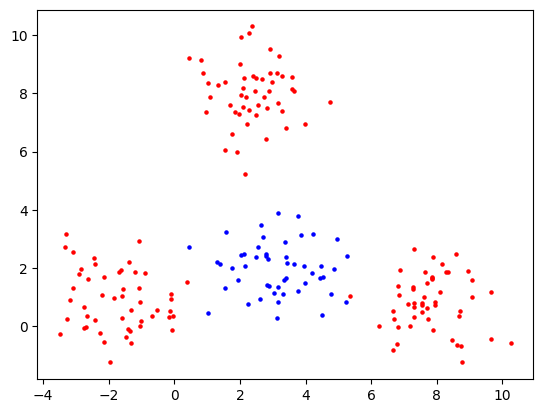

     pcost       dcost       gap    pres   dres
 0: -3.1315e+01 -3.7515e+01  1e+03  2e+01  2e-12
 1: -6.1062e+00 -3.4599e+01  1e+02  2e+00  2e-12
 2: -3.3961e+00 -1.9307e+01  3e+01  4e-01  5e-13
 3: -2.0108e+00 -7.9414e+00  1e+01  1e-01  2e-13
 4: -1.6045e+00 -4.5939e+00  5e+00  5e-02  1e-13
 5: -1.4893e+00 -2.3212e+00  1e+00  1e-02  1e-13
 6: -1.5301e+00 -1.8387e+00  4e-01  3e-03  8e-14
 7: -1.5763e+00 -1.6571e+00  1e-01  5e-04  9e-14
 8: -1.5881e+00 -1.6121e+00  2e-02  2e-16  1e-13
 9: -1.5951e+00 -1.6040e+00  9e-03  2e-16  9e-14
10: -1.5977e+00 -1.6011e+00  3e-03  2e-16  1e-13
11: -1.5993e+00 -1.5994e+00  6e-05  2e-16  1e-13
12: -1.5993e+00 -1.5993e+00  6e-07  2e-16  1e-13
Optimal solution found.


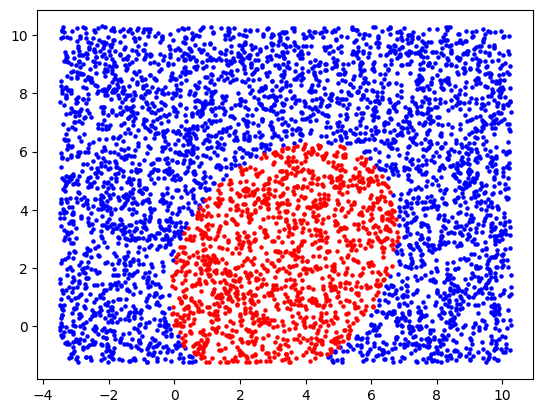

In [ ]:
import numpy as np
from cvxopt import matrix, solvers
import matplotlib.pyplot as plt

# Función para el kernel polinomial
def polynomial_kernel(x, y, orden):
    return (np.dot(x, y) + 1) ** orden

# Generación de datos
n = 50
np.random.seed(0)  # para reproducibilidad
x11 = np.random.randn(n) + 3
x12 = np.random.randn(n) + 2
x21 = np.random.randn(n) - 2
x22 = np.random.randn(n) + 1
x31 = np.random.randn(n) + 2.5
x32 = np.random.randn(n) + 8
x41 = np.random.randn(n) + 8
x42 = np.random.randn(n) + 1
y1 = np.ones(n)
y2 = -np.ones(3 * n)
x = np.vstack([np.hstack([x11, x21, x31, x41]), np.hstack([x12, x22, x32, x42])]).T
y = np.hstack([y1, y2])

# Graficar los datos
plt.figure()
plt.scatter(x[y == -1, 0], x[y == -1, 1], color='r', marker='.', s=20)
plt.scatter(x[y == 1, 0], x[y == 1, 1], color='b', marker='.', s=20)
plt.show()

n_samples, n_features = x.shape

# Preparar la matriz H usando el kernel polinomial
orden = 2  # Orden del polinomio
H = np.zeros((n_samples, n_samples))

for i in range(n_samples):
    for j in range(n_samples):
        H[i, j] = y[i] * y[j] * polynomial_kernel(x[i], x[j], orden)
H = 0.5*H

# Construir otros argumentos para la función qp
q = -np.ones(n_samples)
A = y.reshape((1, -1)).astype(float)
b = np.zeros(1)
G = np.vstack([-np.eye(n_samples), np.eye(n_samples)])
h = np.hstack([np.zeros(n_samples), np.ones(n_samples) * 0.1])



# Resolver el problema de optimización cuadrática
H = matrix(H)
q = matrix(q)
A = matrix(A)
b = matrix(b)
G = matrix(G)
h = matrix(h)



solution = solvers.qp(H, q, G, h, A, b)
alphas = np.array(solution['x']).flatten()

# Realizar la clasificación en datos de prueba
threshold = 1e-5
support_vectors_indices = alphas > threshold
alphas = alphas[support_vectors_indices]
support_vectors_x = x[support_vectors_indices]
support_vectors_y = y[support_vectors_indices]

# Generar datos de prueba
npuntos = 5000
xp1 = np.random.uniform(low=x[:,0].min(), high=x[:,0].max(), size=(npuntos,))
xp2 = np.random.uniform(low=x[:,1].min(), high=x[:,1].max(), size=(npuntos,))
xp = np.vstack([xp1, xp2]).T

# t = alfat.*yt;
# yp = ones(size(xp1));
# for k=1:np
#   d1 = 0;
#   for l=1:na
#     d1 = d1 + t(l)*(xp(k,:)*xt(l,:)'+1)^qk;


yp = np.ones(npuntos)
for i in range(npuntos):
    s = 0
    for alpha, sv_label, sv in zip(alphas, support_vectors_y, support_vectors_x):
        s += alpha * sv_label * polynomial_kernel(xp[i], sv, orden)
    yp[i] = np.sign(s)

# Graficar los datos clasificados
plt.figure()
plt.scatter(xp[yp == -1, 0], xp[yp == -1, 1], color='b', marker='.', s=20)
plt.scatter(xp[yp == 1, 0], xp[yp == 1, 1], color='r', marker='.', s=20)
plt.show()
